In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    auc,
)
from toolbox import (
    Masking,
    compute_ROC_patient_split,
    find_all_indices,
    hot_coding,
)
from toolbox.loading import load_data, load_data_no_norm
from toolbox.visualization import cmap_gradient

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

# set prints off
mask.prints = True

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -5.841877056904085e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
class_task = "cancer_vs_hbd"
class_task = "MC"

In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]


elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)


MC

Healthy: 90 entries
Cancer: 96 entries
Severe dysplasia: 29 entries
Benign: 41 entries
Available cases: ['Benign' 'Cancer' 'Healthy' 'Severe dysplasia']
Coding: -> forward
{'Benign': [1, 0, 0, 0], 'Cancer': [0, 1, 0, 0], 'Healthy': [0, 0, 1, 0], 'Severe dysplasia': [0, 0, 0, 1]}

Inverse mapping: {(1, 0, 0, 0): 'Benign', (0, 1, 0, 0): 'Cancer', (0, 0, 1, 0): 'Healthy', (0, 0, 0, 1): 'Severe dysplasia'}
(256, 31, 7728) (256, 4) (256,)


## Analysis stage: IIVV selection (only)

In [6]:
# load masking selection
Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}

In [7]:
print(len(Mask_sel))

13


In [8]:
for Mname, Msel in Mask_sel.items():
    print(Mname, "\t", Msel)

All 	 all
Long a+ 	 vv_long_across
Long a+ ext. 	 vv_long_across_extended
Med. a+ ext. 	 vv_medium_across_extended
Skip1 close 	 vv_distance_close_skip_1
Adj. close 	 adjacent_close
Med. adj. 	 vv_distance_medium_adj
Adj. far 	 adjacent_far
Skip1 medium 	 skip1_medium
Skip1 far 	 skip1_far
Opp. close 	 opposite_close
Opp. medium 	 opposite_medium
Opp. far 	 opposite_far


Develop new IIVV pattern set from an impedance threshold based on noise floor of data 
Goal would be to filter out patterns that are below that floor 

In [9]:
# Load impedance data, no norm
(
        py_idx,
        patient_no,
        patient_sample,
        Zdata_abs,
        Avg_Cutpats
    ) = load_data_no_norm(path="data", Cutpats_threshold=60)

X_raw = Zdata_abs[select_idx, ...]


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


In [10]:
# want to look at average impedance at each frequency for each sample
avg_Z_fp = np.mean(X_raw,axis=0)
avg_Z_sp = np.mean(X_raw,axis=1)
avg_Z_sf = np.mean(X_raw,axis=2)

std_Z_sf = np.std(X_raw,axis=2)
print("SNR all patterns and samples at each frequency")
print(np.mean(avg_Z_sf/std_Z_sf,axis=0))

print("Average impedance at each frequency")
print(np.mean(avg_Z_sf,axis=0))

# SNR of each pattern 
std_Z_p = np.std(avg_Z_sp,axis=0)
avg_Z_p = np.mean(avg_Z_sp,axis=0)
print("Zeros in std_Z_p:", np.sum(std_Z_p == 0))
epsilon = 1e-10
iivv_snr = avg_Z_p / (std_Z_p + epsilon)

#plt.figure 
#plt.plot(iivv_snr)

# 100 Hz has the lowest SNR surprisingly so that's what we'll use 

SNR all patterns and samples at each frequency
[1.01632466 1.01729623 1.01788568 1.01871762 1.01973595 1.0208792
 1.02205057 1.02388499 1.02082224 1.02558818 1.02700683 1.02596671
 1.02800431 1.03186855 1.03292918 1.0359453  1.04063676 1.04526905
 1.04970866 1.05658387 1.06364394 1.07250305 1.08144579 1.09102113
 1.10165776 1.11178783 1.12232142 1.13259905 1.14220929 1.15181751
 1.16106777]
Average impedance at each frequency
[860.58137387 828.93510918 805.90220612 781.38901158 754.38208302
 724.86952472 692.75813464 652.46714258 624.88732135 587.26365798
 546.43599146 504.26252237 474.21236325 426.89784851 400.67119596
 364.8642016  329.70520641 299.75669493 275.05386084 247.93860059
 225.67674812 205.42448781 187.61771189 171.67942341 157.39849959
 144.65366804 133.18195174 122.79860612 113.26353732 104.3321462
  96.06768589]
Zeros in std_Z_p: 44


In [11]:
Mask_sel.keys()

dict_keys(['All', 'Long a+', 'Long a+ ext.', 'Med. a+ ext.', 'Skip1 close', 'Adj. close', 'Med. adj.', 'Adj. far', 'Skip1 medium', 'Skip1 far', 'Opp. close', 'Opp. medium', 'Opp. far'])

All set to True.
Average II (current injection) distance: 4.536 mm
Average VV (voltage electrode) distance: 2.715 mm
True: 7728 (100.00%)	False: 0(0.00%)
Mask set by IIVV pattern rule.
True: 7728 (100.00%)	False: 0(0.00%)
Average II (current injection) distance across pattern sets: 4.536 mm
Average VV (voltage electrode) distance across pattern sets: 2.715 mm
config: vv_long_across=array([[26, 31,  1, 22],
       [26, 31,  1, 21],
       [26, 31,  2, 21],
       [26, 31,  2, 22],
       [27, 30,  4, 24],
       [27, 30,  4, 25],
       [27, 30,  5, 24],
       [27, 30,  5, 25],
       [28, 33,  1,  5],
       [28, 33,  1, 10],
       [28, 33,  5,  6],
       [28, 33,  6, 10],
       [29, 32, 16, 20],
       [29, 32, 16, 25],
       [29, 32, 20, 21],
       [29, 32, 21, 25]])
Mask set by IIVV pattern rule.
True: 16 (0.21%)	False: 7712(99.79%)
Average II (current injection) distance across pattern sets: 6.162 mm
Average VV (voltage electrode) distance across pattern sets: 4.062 mm
config

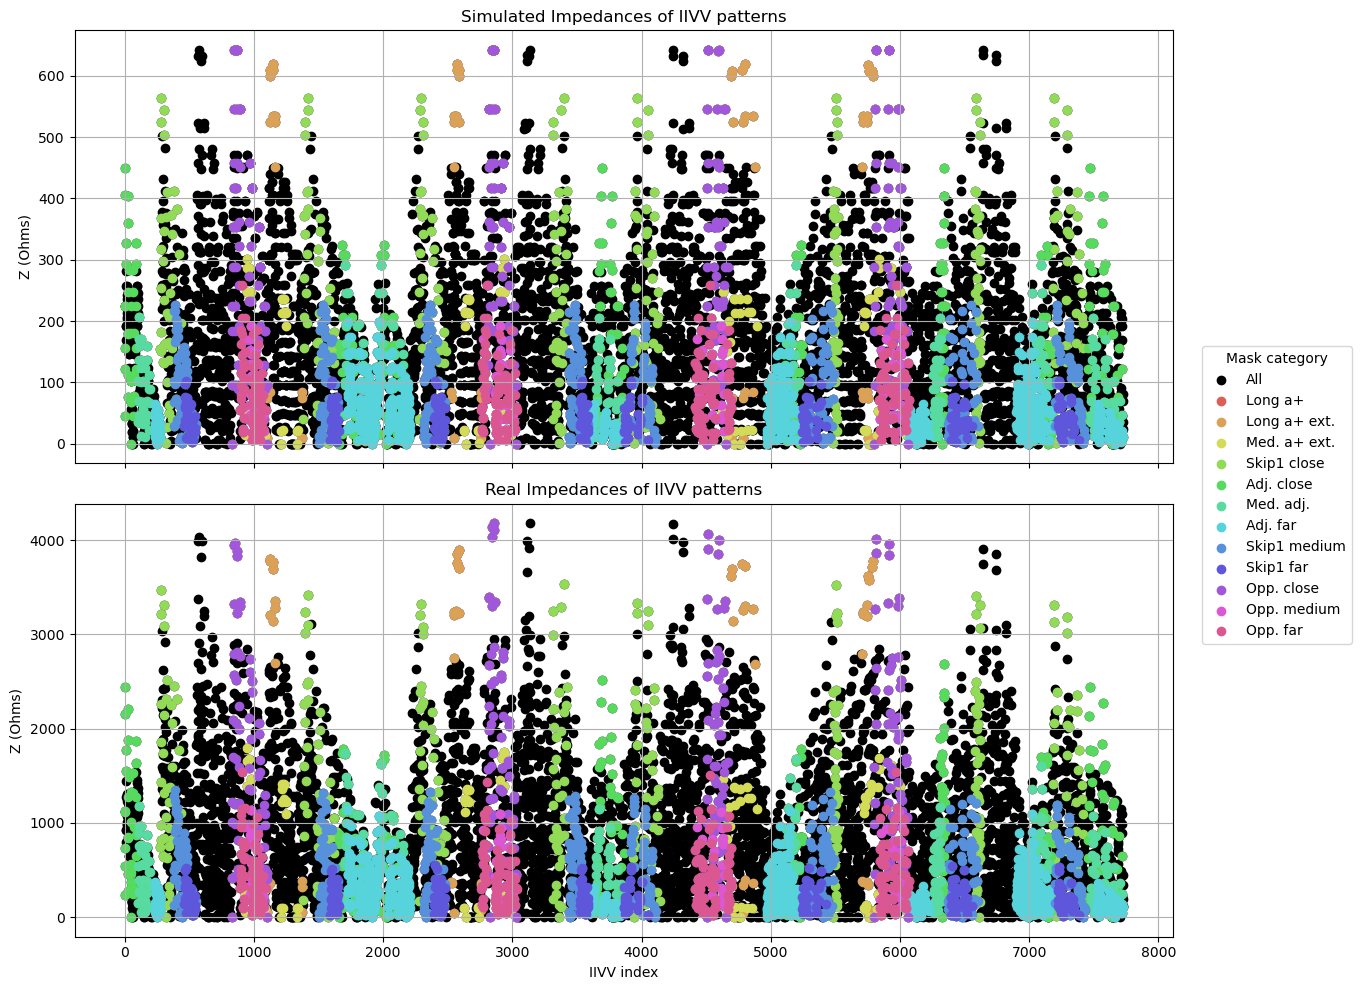

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
Zsim = pd.read_csv("source/Zsim.csv", header=None).squeeze()  # squeeze to Series
Zsim = np.abs(Zsim)
iivv_set = np.arange(len(Zsim))  # indices for each data point

# Assume Mask_sel is a dictionary, keys are mask names, values are masks or "all"
# Assume mask.IIVV_mask(Msel, plot=False) sets mask.mask boolean array for selection

# Set up color palette
categories = list(Mask_sel.keys())
base_palette_seeds = sns.color_palette("hls", n_colors=len(categories) - 1)
palette = {}
i = 0
for cat in categories:
    if cat == "All":
        palette[cat] = (0, 0, 0)  # black for "All"
    else:
        palette[cat] = base_palette_seeds[i]
        i += 1

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(12, 10), sharex=True)

# Plotting simulated data
axs[0].set_title("Simulated Impedances of IIVV patterns")
axs[0].set_ylabel("Z (Ohms)")
axs[0].grid(True)

plotted_labels = set()  # To avoid duplicate legend entries

# Plotting real data
axs[1].set_title("Real Impedances of IIVV patterns")
axs[1].set_xlabel("IIVV index")
axs[1].set_ylabel("Z (Ohms)")
axs[1].grid(True)


# To avoid duplicate legend entries, keep track of plotted labels
plotted_labels = set()
results = {}

for Mname, Msel in Mask_sel.items():
    ii_dist = None
    vv_dist = None 
    
    # compute mask and ii / vv distances
    mask_result, ii_dist, vv_dist = mask.IIVV_mask(Msel, plot=False, update_mask=True)
    Zs_sim = Zsim.values[mask.mask]
    iivv_plot = iivv_set[mask.mask]

    # Real data
    Zs_real = avg_Z_fp[0, mask.mask]
        
    results[Mname] = {"avg_ii_dist": ii_dist, "avg_vv_dist": vv_dist}

    color = palette.get(Mname, (0.5, 0.5, 0.5))  # fallback grey
    
    if Mname not in plotted_labels:
        label = Mname
        plotted_labels.add(Mname)
    else:
        label = None
    
    axs[0].scatter(iivv_plot,Zs_sim, color=color, label=label)
    axs[1].scatter(iivv_plot, Zs_real, color=color, label=None)
        
# Adjust subplot to make space on the right for the legend
plt.subplots_adjust(right=0.8)  # leave 20% space on the right

# Single legend on the right, centered vertically
fig.legend(
    loc='center left',
    bbox_to_anchor=(1.0, 0.5),
    ncol=1,
    title="Mask category"
)

plt.tight_layout()
plt.show()

In [13]:
results

{'All': {'avg_ii_dist': 4.536301229224926, 'avg_vv_dist': 2.71469184708415},
 'Long a+': {'avg_ii_dist': 6.16227766016838,
  'avg_vv_dist': 4.061552812808831},
 'Long a+ ext.': {'avg_ii_dist': 6.16227766016838,
  'avg_vv_dist': 3.158538925939875},
 'Med. a+ ext.': {'avg_ii_dist': 6.16227766016838,
  'avg_vv_dist': 2.0577299858579567},
 'Skip1 close': {'avg_ii_dist': 4.357388321059433,
  'avg_vv_dist': 2.0138986279087185},
 'Adj. close': {'avg_ii_dist': 2.8251407699364424,
  'avg_vv_dist': 1.7952409197821555},
 'Med. adj.': {'avg_ii_dist': 2.8251407699364424,
  'avg_vv_dist': 2.1538357700045583},
 'Adj. far': {'avg_ii_dist': 2.8251407699364424,
  'avg_vv_dist': 2.2834090484209595},
 'Skip1 medium': {'avg_ii_dist': 4.357388321059433,
  'avg_vv_dist': 2.156847427690053},
 'Skip1 far': {'avg_ii_dist': 4.357388321059433,
  'avg_vv_dist': 1.5765832116555925},
 'Opp. close': {'avg_ii_dist': 6.16227766016838,
  'avg_vv_dist': 2.4779909963846887},
 'Opp. medium': {'avg_ii_dist': 6.1622776601683

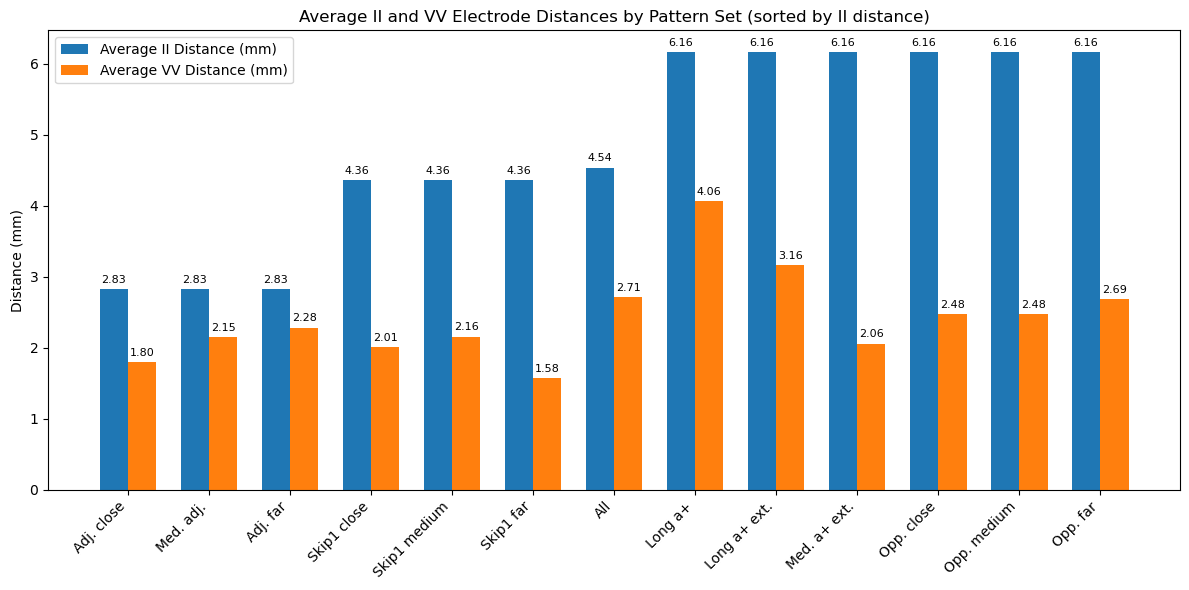

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Remove 'all' from results if present, since it has no valid distances
#filtered_results = {k: v for k, v in results.items() if k != "All"}
filtered_results = results

# Extract patterns and distances
patterns = list(filtered_results.keys())
ii_dists = [filtered_results[p]['avg_ii_dist'] if filtered_results[p]['avg_ii_dist'] is not None else 0 for p in patterns]
vv_dists = [filtered_results[p]['avg_vv_dist'] if filtered_results[p]['avg_vv_dist'] is not None else 0 for p in patterns]

# Sort by average II distance
sorted_indices = np.argsort(ii_dists)
patterns_sorted = [patterns[i] for i in sorted_indices]
ii_dists_sorted = [ii_dists[i] for i in sorted_indices]
vv_dists_sorted = [vv_dists[i] for i in sorted_indices]

x = np.arange(len(patterns_sorted))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
bars_ii = ax.bar(x - width/2, ii_dists_sorted, width, label='Average II Distance (mm)', color='tab:blue')
bars_vv = ax.bar(x + width/2, vv_dists_sorted, width, label='Average VV Distance (mm)', color='tab:orange')

ax.set_ylabel('Distance (mm)')
ax.set_title('Average II and VV Electrode Distances by Pattern Set (sorted by II distance)')
ax.set_xticks(x)
ax.set_xticklabels(patterns_sorted, rotation=45, ha='right')
ax.legend()

for bar in bars_ii:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=8)

for bar in bars_vv:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

config: vv_long_across=array([[26, 31,  1, 22],
       [26, 31,  1, 21],
       [26, 31,  2, 21],
       [26, 31,  2, 22],
       [27, 30,  4, 24],
       [27, 30,  4, 25],
       [27, 30,  5, 24],
       [27, 30,  5, 25],
       [28, 33,  1,  5],
       [28, 33,  1, 10],
       [28, 33,  5,  6],
       [28, 33,  6, 10],
       [29, 32, 16, 20],
       [29, 32, 16, 25],
       [29, 32, 20, 21],
       [29, 32, 21, 25]])
Mask set by IIVV pattern rule.
True: 16 (0.21%)	False: 7712(99.79%)
config: vv_long_across_extended={'26_31': [1, 2, 3, 21, 22, 23], '27_30': [3, 4, 5, 23, 24, 25], '28_33': [1, 5, 6, 10, 11, 15], '29_32': [11, 15, 16, 20, 21, 25], '30_26': [1, 2, 3, 23, 24, 25], '31_27': [3, 4, 5, 21, 22, 23], '32_28': [5, 10, 11, 15, 16, 21], '33_29': [1, 6, 11, 15, 20, 25]}
Mask set by IIVV pattern rule.
True: 120 (1.55%)	False: 7608(98.45%)
config: vv_medium_across_extended={'26_31': [6, 7, 8, 16, 17, 18], '27_30': [8, 9, 10, 18, 19, 20], '28_33': [2, 4, 7, 9, 12, 14], '29_32': [12,

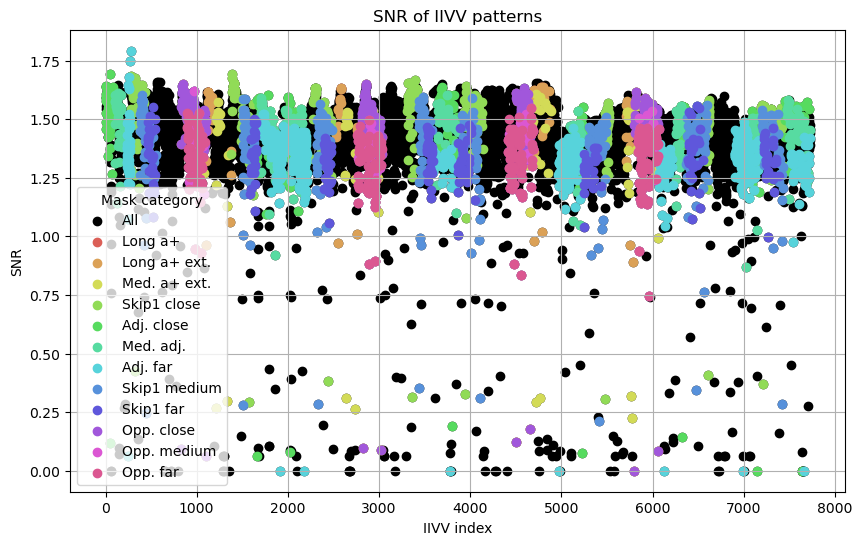

In [57]:
# Plot iivv set SNR 

plt.figure(figsize=(10, 6))
plt.title("SNR of IIVV patterns")
plt.xlabel("IIVV index")
plt.ylabel("SNR")
plt.grid(True)

plotted_labels = set()

for Mname, Msel in Mask_sel.items():
    if Msel == "all":
        Z_snr = iivv_snr
        iivv_plot = iivv_set
        
    else:
        mask.IIVV_mask(Msel, plot=False)  # presumably sets mask.mask
        Z_snr = iivv_snr[mask.mask]
        iivv_plot = iivv_set[mask.mask]
        

    color = palette.get(Mname, (0.5, 0.5, 0.5))  # fallback grey
    
    # Only add label once per category in legend
    label = Mname if Mname not in plotted_labels else None
    plt.scatter(iivv_plot, Z_snr, color=color, label=label)
    plotted_labels.add(Mname)
    
        
plt.legend(title="Mask category")
plt.show()

# Testing z threshold to find impedance ranges that improve AUCs

In [16]:
import numpy as np
import pandas as pd
from sklearn.metrics import auc, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import label_binarize
from sklearn.svm import SVC
from toolbox.results import Results_data_loading
from tqdm import tqdm

In [17]:
min_z = 1 
max_z = np.max(avg_Z_fp[0,:])
print(f"Max z threshold: {max_z}")
z_thresholds = np.linspace(min_z, max_z, num=100)
n_trials = 5
n_splits = 5

class_task = "healthy_vs_cancer"
# Get labels for task 
select_idx = find_all_indices(
    labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
)
labels = labels_healthy_vs_cancer[select_idx]

Case = patient_no[select_idx]
X_task = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

Y_labels = np.argmax(Y, axis=1)
classes = np.unique(Y_labels)
n_classes = len(classes)

# dict for trial stats 
stats = []

trial_idx = 1
for rs in tqdm(range(n_trials)):
    m = SVC(probability=True, random_state=0)
    cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
    
    for z_thresh in z_thresholds:
        above_threshold = avg_Z_fp[0,:] <= z_thresh
        num_iivv = np.sum(above_threshold)
        
        # Select columns/patterns for this threshold
        X_thresholded = X_task[:, :, above_threshold]
        X_tmp = X_thresholded.reshape(X_thresholded.shape[0], -1)

        aucs_per_fold = []
                          
        for train_idx, test_idx in cv.split(X_tmp, Y, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
              
            m.fit(X_train, y_train)
              
            probs = m.predict_proba(X_test)  # shape (n_samples, n_classes)
            
            if n_classes == 2:
                roc_auc = roc_auc_score(y_test, probs[:, 1])
            else:
                # Binarize true labels
                y_bin = label_binarize(y_test, classes=classes)  # shape (n_samples, n_classes)
                # Micro-average ROC
                fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
                roc_auc = auc(fpr, tpr)

                # Flip AUC if < 0.5
                if roc_auc < 0.5:
                    fpr, tpr = 1 - fpr, 1 - tpr
                    roc_auc = 1 - roc_auc

            aucs_per_fold.append(roc_auc)
        
              
        mean_auc_trial = np.mean(aucs_per_fold)
        print(f"Threshold {z_thresh}, num iivvs: {num_iivv}, trial {trial_idx},  mean auc: {mean_auc_trial}, fold aucs: {aucs_per_fold}")
        
        stats.append({
            "Task": class_task,
            "z_threshold": z_thresh,
            "IIVV": num_iivv,
            "rs": rs,
            "auc": mean_auc_trial,
            "fold auc": aucs_per_fold
        })
    print(f"Trial {trial_idx} complete")  
    trial_idx += 1
             
# Convert to DataFrame for saving and plotting
df_stats = pd.DataFrame(stats)

# Save to CSV
csv_fname = f"results/IIVV-z_threshold_{min_z}_{max_z}_{class_task}.csv"
df_stats.to_csv(csv_fname, index=False)
print(f"Saved results to {csv_fname}")


Max z threshold: 4179.812907623587
Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{'Cancer': [1, 0], 'Healthy': [0, 1]}

Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(256, 31, 7728) (186, 2) (186,)


  0%|          | 0/5 [00:00<?, ?it/s]

Threshold 1.0, num iivvs: 132, trial 1,  mean auc: 0.8315235603648461, fold aucs: [0.7413461538461539, 0.757703081232493, 0.9463667820069204, 0.831578947368421, 0.8806228373702422]


  0%|          | 0/5 [00:04<?, ?it/s]


KeyboardInterrupt: 

In [24]:
from glob import glob
# Load in results
# Load data
#df_stats = pd.read_csv("results/IIVV-z_threshold_1_3811_healthy_vs_cancer.csv") 
#df_stats


files = glob("results/IIVV-z_threshold_1_*.csv")

dfs = []
df_stats = []

for file in files:
    df = pd.read_csv(file)
    dfs.append(df)

df_stats = pd.concat(dfs, ignore_index=True)

df_stats
# number of iivv patterns in best performing one
#filtered_df = df_stats[df_stats['z_threshold'] == 384.95261399498247]
#filtered_df['IIVV']

,Task,z_threshold,IIVV,rs,auc
0,healthy_vs_cancer,1.000000,130,0,0.830446
1,healthy_vs_cancer,39.485160,304,0,0.845126
2,healthy_vs_cancer,77.970321,517,0,0.866999
3,healthy_vs_cancer,116.455481,892,0,0.869282
4,healthy_vs_cancer,154.940642,1221,0,0.886728
...,...,...,...,...,...
1495,cancer_vs_hbd,4008.059659,7718,4,0.851370
1496,cancer_vs_hbd,4050.239234,7722,4,0.851792
1497,cancer_vs_hbd,4092.418810,7723,4,0.851792
1498,cancer_vs_hbd,4134.598385,7724,4,0.852170


Max AUC with z-threshold: 385.8516038939724
Plot saved to healthy_vs_cancer_auc_vs_zthreshold.pdf


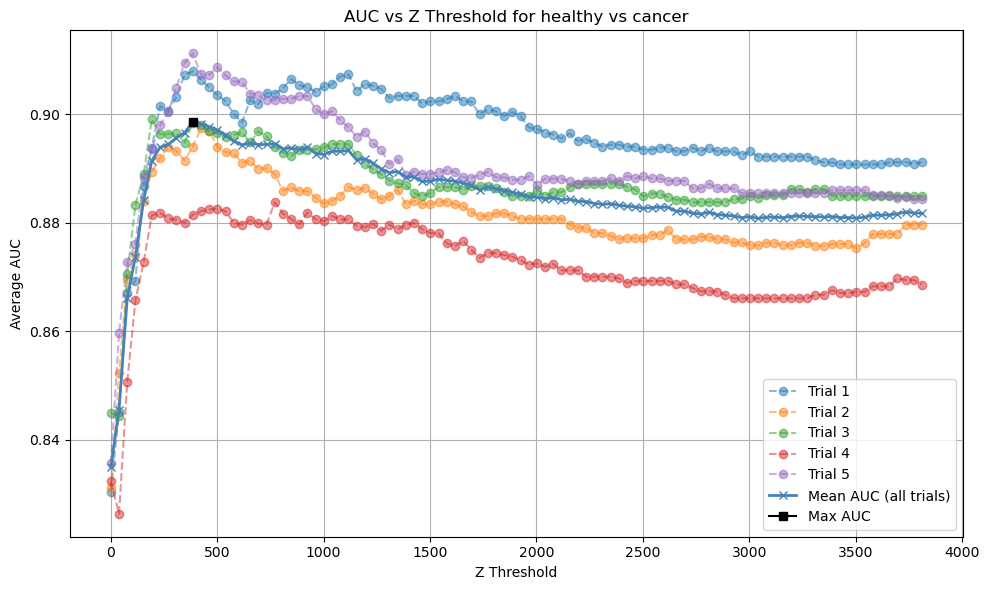

Max AUC with z-threshold: 422.7957535886625
Plot saved to cancer_vs_hbd_auc_vs_zthreshold.pdf


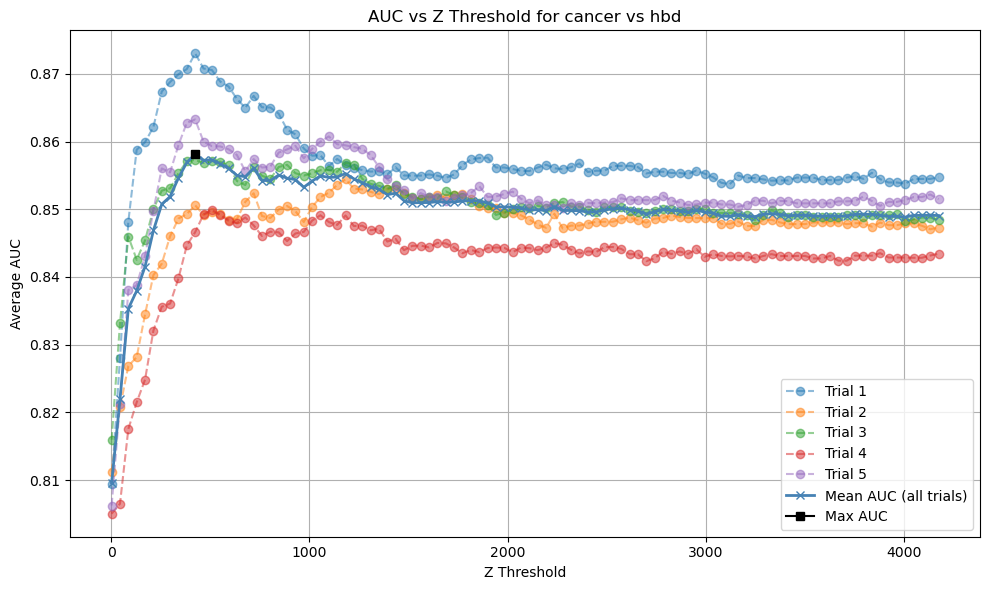

Max AUC with z-threshold: 385.8516038939724
Plot saved to MC_auc_vs_zthreshold.pdf


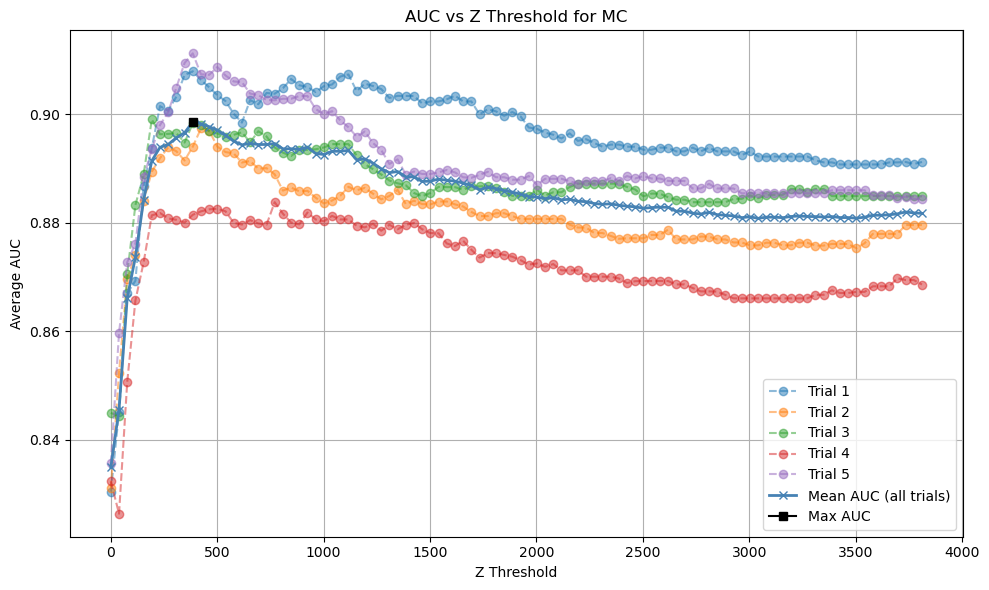

In [28]:
class_task = ['healthy_vs_cancer', 'cancer_vs_hbd', 'MC']

for task in class_task: 

    # filter by current task 
    task_stats = df_stats[df_stats['Task'] == task]
    
    # Replace underscores with spaces for display in title
    display_task = task.replace('_', ' ')
    
    plt.figure(figsize=(10, 6))
    plt.title(f"AUC vs Z Threshold for {display_task}")
    plt.xlabel("Z Threshold")
    plt.ylabel("Average AUC")
    plt.grid(True)
    
    # Plot each trial's AUC as a line    
    # We pivot so that each column is a trial rs, index=z_threshold
    aucs_pivot = task_stats.pivot(index="z_threshold", columns="rs", values="auc")

    for trial_idx in aucs_pivot.columns:
        plt.plot(aucs_pivot.index, aucs_pivot[trial_idx], 
                 alpha=0.5, linestyle='--', marker='o', label=f"Trial {trial_idx + 1}")

    # Compute average AUC across trials for each threshold
    mean_aucs_per_threshold = task_stats.groupby("z_threshold")["auc"].mean()
    plt.plot(mean_aucs_per_threshold.index, mean_aucs_per_threshold.values, 
             marker="x", color="steelblue", linewidth=2, label="Mean AUC (all trials)")
    # plot the max auc of the mean
    max_auc = mean_aucs_per_threshold.max()
    idx_max = mean_aucs_per_threshold.idxmax()
    print(f"Max AUC with z-threshold: {idx_max}")
    plt.plot(idx_max,max_auc,marker='s',color='black', label='Max AUC')

    plt.legend()
    plt.tight_layout()

    save_flg = True
    if save_flg:
        plt.savefig(f"{task}_auc_vs_zthreshold.pdf", bbox_inches="tight")
        print(f"Plot saved to {task}_auc_vs_zthreshold.pdf")

    plt.show()

In [9]:
results = []
numXparams = []
n_trials = 10

for Mname, Msel in Mask_sel.items():
    if Msel == "all":
        X_tmp = X[:, :, :]
    else:
        # apply mask
        mask.IIVV_mask(Msel, plot=False)
        X_tmp = X[:, :, mask.mask]
    numXparams.append({"Mask": Mname, "n_params": X_tmp.shape[1] * X_tmp.shape[2]})

    for trial in range(n_trials):
        print("Trial:", trial, "\n\t", Mname)
        avg_roc_auc, _ = compute_ROC_patient_split(
            X_tmp,
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Mask": Mname, "Trial": trial + 1, "avg. ROC AUC": avg_roc_auc})

df_results = pd.DataFrame(results)
df_params = pd.DataFrame(numXparams)

df_results.to_csv(f"results/IIVV-analysis_{class_task}.csv", index=False)
df_params.to_csv(f"results/IIVV-analysis_{class_task}_params.csv", index=False)

Trial: 0 
	 All
Train patients: [44 63  3 72 46 49  6 99 83 77 61 81 90 69 52 28 18 57 64 75  1 62 43 42
  4 15 17 41 39  5 91 60  0 35 29 51 11 36 23 53 10 32 67 58 80 86 33 85
 14 89 19 30 50 97 98 70 20 94 73 78 25 38 82 47 40 66 59 12 71 88 37 21
 84  9 96 68 65 48 45]
Test patients: [27 87  2 56 76 93 16 74 55 95 54 92 79 13  7 31 22 24 34  8]
Trial: 1 
	 All
Train patients: [ 2 45 60 56 19 39 94 28 41 99 37 53 75 71 40 47 67 23 35 86 97 68 15 83
 42 91 27 98 44 54 24  4 57 50 21 87  3 74 31 66 70 43 48 52 95  8 61  0
 90 58 22 62 64  7 96 13 69 85 14 30 29 11 18 20 51 25  6 72 77  1 16 65
 80  5 76  9 73 12 38]
Test patients: [93 84 33 81 79 17 36 82 89 92 46 34 55 78 63 32 59 49 88 10]
Trial: 2 
	 All
Train patients: [36 11 84 45 97  5 25 77 74 63 66  1 18 49 37 78  6 75 91 10 12 54 87 55
 95 33 19 27 61 56  9 96 17 60 58 42 65 46 72  8 71 82 90 98 88 80 51 53
 67 85 47 69 70 81 59 34 39 52 43  4 68 40 38 20 32 64 48 86 93 50 35  7
 76 83 44 22 73 15 41]
Test patients: [94 31 57

/home/jt292/miniconda3/envs/TF2_19/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1201: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/home/jt292/miniconda3/envs/TF2_19/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


config: vv_long_across=array([[26, 31,  1, 22],
       [26, 31,  1, 21],
       [26, 31,  2, 21],
       [26, 31,  2, 22],
       [27, 30,  4, 24],
       [27, 30,  4, 25],
       [27, 30,  5, 24],
       [27, 30,  5, 25],
       [28, 33,  1,  5],
       [28, 33,  1, 10],
       [28, 33,  5,  6],
       [28, 33,  6, 10],
       [29, 32, 16, 20],
       [29, 32, 16, 25],
       [29, 32, 20, 21],
       [29, 32, 21, 25]])
Mask set by IIVV pattern rule.
True: 16 (0.21%)	False: 7712(99.79%)
Trial: 0 
	 Long a+
Train patients: [44 63  3 72 46 49  6 99 83 77 61 81 90 69 52 28 18 57 64 75  1 62 43 42
  4 15 17 41 39  5 91 60  0 35 29 51 11 36 23 53 10 32 67 58 80 86 33 85
 14 89 19 30 50 97 98 70 20 94 73 78 25 38 82 47 40 66 59 12 71 88 37 21
 84  9 96 68 65 48 45]
Test patients: [27 87  2 56 76 93 16 74 55 95 54 92 79 13  7 31 22 24 34  8]
Trial: 1 
	 Long a+
Train patients: [ 2 45 60 56 19 39 94 28 41 99 37 53 75 71 40 47 67 23 35 86 97 68 15 83
 42 91 27 98 44 54 24  4 57 50 21 87  3 74 3

/home/jt292/miniconda3/envs/TF2_19/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1201: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/home/jt292/miniconda3/envs/TF2_19/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Trial: 1 
	 Long a+ ext.
Train patients: [ 2 45 60 56 19 39 94 28 41 99 37 53 75 71 40 47 67 23 35 86 97 68 15 83
 42 91 27 98 44 54 24  4 57 50 21 87  3 74 31 66 70 43 48 52 95  8 61  0
 90 58 22 62 64  7 96 13 69 85 14 30 29 11 18 20 51 25  6 72 77  1 16 65
 80  5 76  9 73 12 38]
Test patients: [93 84 33 81 79 17 36 82 89 92 46 34 55 78 63 32 59 49 88 10]
Trial: 2 
	 Long a+ ext.
Train patients: [36 11 84 45 97  5 25 77 74 63 66  1 18 49 37 78  6 75 91 10 12 54 87 55
 95 33 19 27 61 56  9 96 17 60 58 42 65 46 72  8 71 82 90 98 88 80 51 53
 67 85 47 69 70 81 59 34 39 52 43  4 68 40 38 20 32 64 48 86 93 50 35  7
 76 83 44 22 73 15 41]
Test patients: [94 31 57 24 16 23  2 28 29 13 99 92 89 14  0 21  3 30 62 79]
Trial: 3 
	 Long a+ ext.
Train patients: [96 12  8  4 79 54 17 65 80 43  5 13 32 71 11 60 88 33 85 16 28 36 37 69
 90 62 76 68 47 92 74 66 18 91 58 95 55 56 29 53 84 89 50 31 87 38 49 34
 44  7 63 99 30 70 52  1 61 64  2 67 22 82 27 14 40 45 20 39 94 10 42 75
 19 21  0 73 57  3 2

...

/home/jt292/miniconda3/envs/TF2_19/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1201: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/home/jt292/miniconda3/envs/TF2_19/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


ii_pattern=[[np.int64(26), np.int64(30)], [np.int64(27), np.int64(31)], [np.int64(28), np.int64(32)], [np.int64(29), np.int64(33)], [np.int64(30), np.int64(26)], [np.int64(31), np.int64(27)], [np.int64(32), np.int64(28)], [np.int64(33), np.int64(29)]]
config: vv_distance_medium_opp={'26_30': [5, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 21], '27_31': [1, 6, 7, 8, 11, 12, 13, 14, 15, 18, 19, 20, 25], '28_32': [1, 2, 3, 7, 8, 12, 13, 14, 18, 19, 23, 24, 25], '29_33': [3, 4, 5, 8, 9, 12, 13, 14, 17, 18, 21, 22, 23], '30_26': [5, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 21], '31_27': [1, 6, 7, 8, 11, 12, 13, 14, 15, 18, 19, 20, 25], '32_28': [1, 2, 3, 7, 8, 12, 13, 14, 18, 19, 23, 24, 25], '33_29': [3, 4, 5, 8, 9, 12, 13, 14, 17, 18, 21, 22, 23]}
Mask set by IIVV pattern rule.
True: 264 (3.42%)	False: 7464(96.58%)
Trial: 0 
	 Opp. medium
Train patients: [44 63  3 72 46 49  6 99 83 77 61 81 90 69 52 28 18 57 64 75  1 62 43 42
  4 15 17 41 39  5 91 60  0 35 29 51 11 36 23 53 10 32 67 58 80 

/home/jt292/miniconda3/envs/TF2_19/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1201: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/home/jt292/miniconda3/envs/TF2_19/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


ii_pattern=[[np.int64(26), np.int64(30)], [np.int64(27), np.int64(31)], [np.int64(28), np.int64(32)], [np.int64(29), np.int64(33)], [np.int64(30), np.int64(26)], [np.int64(31), np.int64(27)], [np.int64(32), np.int64(28)], [np.int64(33), np.int64(29)]]
config: vv_distance_far_opp={'26_30': [4, 5, 9, 10, 14, 15, 11, 12, 16, 17, 21, 22], '27_31': [1, 2, 6, 7, 11, 12, 14, 15, 19, 20, 24, 25], '28_32': [1, 2, 3, 6, 7, 8, 18, 19, 20, 23, 24, 25], '29_33': [3, 4, 5, 8, 9, 10, 16, 17, 18, 21, 22, 23], '30_26': [4, 5, 9, 10, 14, 15, 11, 12, 16, 17, 21, 22], '31_27': [1, 2, 6, 7, 11, 12, 14, 15, 19, 20, 24, 25], '32_28': [1, 2, 3, 6, 7, 8, 18, 19, 20, 23, 24, 25], '33_29': [3, 4, 5, 8, 9, 10, 16, 17, 18, 21, 22, 23]}
Mask set by IIVV pattern rule.
True: 264 (3.42%)	False: 7464(96.58%)
Trial: 0 
	 Opp. far
Train patients: [44 63  3 72 46 49  6 99 83 77 61 81 90 69 52 28 18 57 64 75  1 62 43 42
  4 15 17 41 39  5 91 60  0 35 29 51 11 36 23 53 10 32 67 58 80 86 33 85
 14 89 19 30 50 97 98 70 20 94 

/home/jt292/miniconda3/envs/TF2_19/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1201: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/home/jt292/miniconda3/envs/TF2_19/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


In [10]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params.csv")

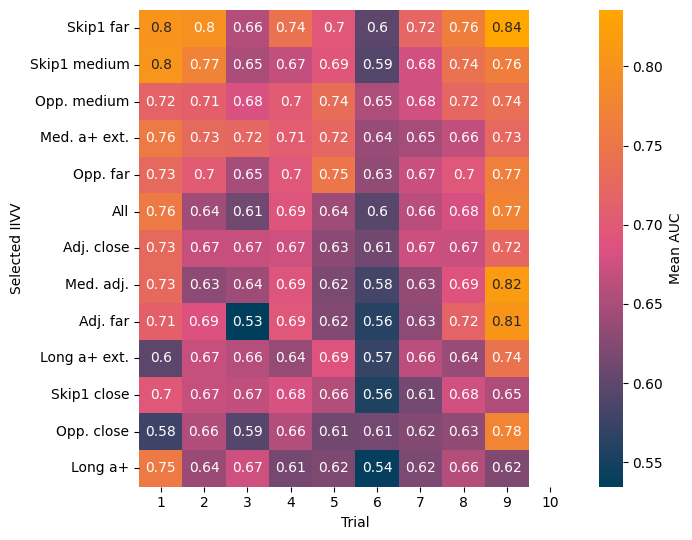

In [11]:
# --- Heatmap figure ---
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

mask_means = df_pivot.mean(axis=1)
# Sort descending by mean ROC AUC
order = mask_means.sort_values(ascending=False).index.tolist()
df_pivot = df_pivot.reindex(order)
# save
np.savez(
    f"results/Top_IIVV_masks_{class_task}.npz",
    maskmeans_order=mask_means[order],
    Mask_ranks=mask_means[order].keys(),
)
fig1, ax0 = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    df_pivot,
    annot=True,
    cmap=cmap_gradient,
    cbar_kws={"label": "Mean AUC"},
    ax=ax0,
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial")
plt.tight_layout()
plt.savefig(f"results/IIVV_sel_heatmap_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [12]:
df_pivot

Trial,1,2,3,4,5,6,7,8,9,10
Mask,,,,,,,,,,
Skip1 far,0.803673,0.797173,0.656719,0.743795,0.696667,0.597907,0.722401,0.764502,0.835565,NaN
Skip1 medium,0.804927,0.773207,0.650841,0.666742,0.694167,0.592090,0.676912,0.742779,0.764835,NaN
Opp. medium,0.715885,0.711144,0.682097,0.703593,0.735278,0.651218,0.675730,0.723307,0.737218,NaN
Med. a+ ext.,0.755923,0.726920,0.723557,0.707323,0.723472,0.637589,0.647230,0.664825,0.725769,NaN
Opp. far,0.726917,0.701969,0.648537,0.695332,0.748611,0.634249,0.671029,0.695045,0.767343,NaN
All,0.755634,0.644081,0.611947,0.691305,0.641667,0.595166,0.660587,0.679277,0.774025,NaN
Adj. close,0.726902,0.670777,0.670936,0.673777,0.628889,0.611613,0.673075,0.671180,0.722715,NaN
Med. adj.,0.727308,0.629998,0.641001,0.691606,0.618750,0.580436,0.634837,0.689211,0.815561,NaN
Adj. far,0.711435,0.686095,0.534567,0.694775,0.622917,0.561645,0.630806,0.716164,0.805822,NaN


In [13]:
print("Ranked by best preformance")
print(mask_means[order])

Ranked by best preformance
Mask
Skip1 far       0.735378
Skip1 medium    0.707389
Opp. medium     0.703941
Med. a+ ext.    0.701401
Opp. far        0.698781
All             0.672632
Adj. close      0.672207
Med. adj.       0.669856
Adj. far        0.662692
Long a+ ext.    0.652142
Skip1 close     0.652095
Opp. close      0.637940
Long a+         0.637264
dtype: float64


In [14]:
df_plot

,Mask,n_params,avg. ROC AUC
0,All,239568,0.672632
1,Long a+,496,0.637264
2,Long a+ ext.,3720,0.652142
3,Med. a+ ext.,3720,0.701401
4,Skip1 close,11160,0.652095
5,Adj. close,9052,0.672207
6,Med. adj.,11997,0.669856
7,Adj. far,20460,0.662692
8,Skip1 medium,13640,0.707389
9,Skip1 far,6944,0.735378


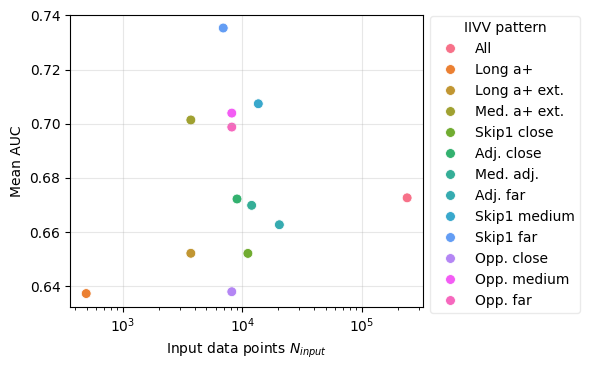

In [15]:
categories = df_plot["Mask"].unique()
base_palette = sns.color_palette(palette="hls", n_colors=len(categories) - 1)
palette = {}
i = 0
for cat in categories:
    if cat == "All":
        palette[cat] = "black"
    else:
        palette[cat] = base_palette[i]
        i += 1

fig2, ax1 = plt.subplots(figsize=(6, 3.8))
sns.scatterplot(
    data=df_plot,
    x="n_params",
    y="avg. ROC AUC",
    hue="Mask",
    palette=palette,
    s=50,
    ax=ax1,
)
ax1.set_xscale("log")
ax1.set_xlabel("Input data points $N_{input}$")
ax1.set_ylabel("Mean AUC")
ax1.grid(alpha=0.3)
ax1.legend(
    title="IIVV pattern", framealpha=0.4, bbox_to_anchor=(1, 1.02), loc="upper left"
)

plt.tight_layout()
plt.savefig(f"results/IIVV_sel_scatter_{class_task}.pdf", bbox_inches="tight")
plt.show()

## Take heuristically selected IIVV pattern

In [16]:
# load masking selection
tmp = np.load(f"results/Top_IIVV_masks_{class_task}.npz", allow_pickle=True)
Mask_ranks = tmp["Mask_ranks"][:4]

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}
Mask_sel = {k: v for k, v in Mask_sel.items() if k in Mask_ranks}

In [17]:
# add baseline pattern
Mask_sel["All"] = "all"

In [18]:
for Mname, Msel in Mask_sel.items():
    print(Mname, "\t", Msel)

Med. a+ ext. 	 vv_medium_across_extended
Skip1 medium 	 skip1_medium
Skip1 far 	 skip1_far
Opp. medium 	 opposite_medium
All 	 all


In [19]:
results = []
numXparams = []
for Mname, Msel in Mask_sel.items():
    mask.IIVV_mask(Msel, plot=False)
    # apply mask
    X_tmp = X[:, :, mask.mask]
    numXparams.append({"Mask": Mname, "n_params": X_tmp.shape[1] * X_tmp.shape[2]})

    for trial in range(7):
        print("Trial:", trial, "\n\t", Mname)
        avg_roc_auc, _ = compute_ROC_patient_split(
            X_tmp,
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Mask": Mname, "Trial": trial + 1, "avg. ROC AUC": avg_roc_auc})

df_results = pd.DataFrame(results)
df_params = pd.DataFrame(numXparams)

df_results.to_csv(f"results/IIVV-analysis_{class_task}_sm.csv", index=False)
df_params.to_csv(f"results/IIVV-analysis_{class_task}_params_sm.csv", index=False)

config: vv_medium_across_extended={'26_31': [6, 7, 8, 16, 17, 18], '27_30': [8, 9, 10, 18, 19, 20], '28_33': [2, 4, 7, 9, 12, 14], '29_32': [12, 14, 17, 19, 22, 24], '30_26': [6, 7, 8, 18, 19, 20], '31_27': [8, 9, 10, 16, 17, 18], '32_28': [12, 14, 17, 19, 22, 24], '33_29': [2, 7, 12, 14, 19, 24]}
Mask set by IIVV pattern rule.
True: 120 (1.55%)	False: 7608(98.45%)
Trial: 0 
	 Med. a+ ext.
Train patients: [44 63  3 72 46 49  6 99 83 77 61 81 90 69 52 28 18 57 64 75  1 62 43 42
  4 15 17 41 39  5 91 60  0 35 29 51 11 36 23 53 10 32 67 58 80 86 33 85
 14 89 19 30 50 97 98 70 20 94 73 78 25 38 82 47 40 66 59 12 71 88 37 21
 84  9 96 68 65 48 45]
Test patients: [27 87  2 56 76 93 16 74 55 95 54 92 79 13  7 31 22 24 34  8]
Trial: 1 
	 Med. a+ ext.
Train patients: [ 2 45 60 56 19 39 94 28 41 99 37 53 75 71 40 47 67 23 35 86 97 68 15 83
 42 91 27 98 44 54 24  4 57 50 21 87  3 74 31 66 70 43 48 52 95  8 61  0
 90 58 22 62 64  7 96 13 69 85 14 30 29 11 18 20 51 25  6 72 77  1 16 65
 80  5 76  9

In [20]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}_sm.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params_sm.csv")

In [21]:
Mask_sel.keys()

dict_keys(['Med. a+ ext.', 'Skip1 medium', 'Skip1 far', 'Opp. medium', 'All'])

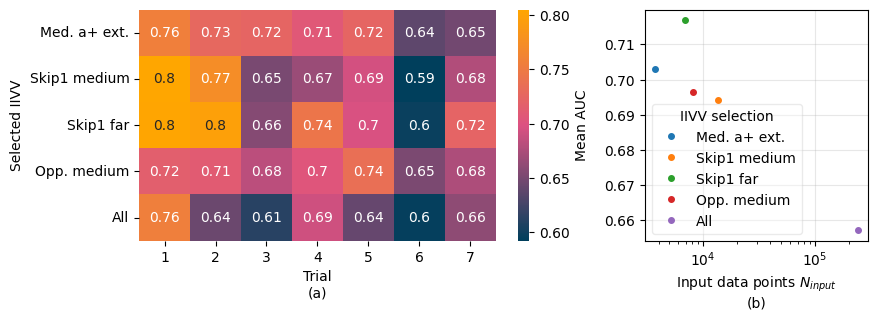

In [22]:
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

fig = plt.figure(figsize=(9.4, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
# defined order
# order = [
#    "Skip1 medium",
#    "Skip1 far",
#    "Opp. medium",
#    "Long a+",
#    "All",
# ]
order = Mask_sel.keys()
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Average AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Mask"],
        markersize=8,
    )
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.set_xscale("log")
# ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

ax1.legend(title="IIVV selection", framealpha=0.4)
plt.savefig(f"results/IIVV_sel_perf_{class_task}_sm.pdf", bbox_inches="tight")
plt.show()

In [23]:
df_plot

,Mask,n_params,avg. ROC AUC
0,Med. a+ ext.,3720,0.703145
1,Skip1 medium,13640,0.694126
2,Skip1 far,6944,0.716905
3,Opp. medium,8184,0.696421
4,All,239568,0.657198


___

## Statistical impact of IIVV maskimport numpy as np

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import auc, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox.results import Results_data_loading
from tqdm import tqdm
from sklearn.preprocessing import label_binarize
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel

IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}

tasks = ["healthy_vs_cancer"] 


for class_task in tasks:
    stats = []
    print(class_task)
    X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
        class_task, data_augmentation=False
    )
    classes = np.unique(Y_labels)
    n_classes = len(classes)
    
    for Msel in Mask_sel.keys():
        if Msel == "All":
            X_tmp = X.reshape(X.shape[0], -1)
        else:
            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            X_tmp = X[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
        for rs in tqdm(range(20)):
            m = SVC(probability=True, random_state=0)
            cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
            for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
                X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
                y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
                m.fit(X_train, y_train)
                probs = m.predict_proba(X_test)  # shape (n_samples, n_classes)
                if n_classes == 2:
                    roc_auc = roc_auc_score(y_test, probs[:, 1])
                else:
                    # Binarize true labels
                    y_bin = label_binarize(y_test, classes=classes)  # shape (n_samples, n_classes)
                    # Micro-average ROC
                    fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
                    roc_auc = auc(fpr, tpr)
                    
                    # Flip AUC if < 0.5
                    if roc_auc < 0.5:
                        fpr, tpr = 1 - fpr, 1 - tpr
                        roc_auc = 1 - roc_auc
                    
                stats.append({"Task": class_task, "IIVV": Msel, "rs": rs, "auc": roc_auc})

    df_stats = pd.DataFrame(stats)
    df_stats.to_csv(f"results/IIVV-analysis_{class_task}_statistics.csv", index=False)